In [2]:
import pandas as pd

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.shape

(99441, 8)

In [5]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [7]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [8]:
orders.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:
orders["order_status"].unique()

<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [10]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [11]:
orders["order_status"].value_counts(normalize=True) * 100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [12]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [13]:
orders[orders["order_delivered_customer_date"].isnull()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [14]:
orders[
    orders["order_delivered_customer_date"].isnull()
    & (orders["order_status"] == "delivered")
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


### Finding: Missing Delivery Dates

The dataset contains 2,965 orders without a customer delivery date. Most are associated with statuses other than `delivered`. However, 8 orders are marked as `delivered` despite having no recorded customer delivery date. Of these, 7 have a carrier delivery date, while 1 is missing both delivery dates.

These records may indicate incomplete delivery tracking or data-quality issues and should be considered when analyzing delivery performance.

In [15]:
orders["order_id"].duplicated().sum()

np.int64(0)

### Finding: Duplicate Orders

The orders dataset contains no duplicate `order_id` values. Each order has a unique identifier, so there are no duplicate order records based on this column.

In [16]:
orders[[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].dtypes

order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [17]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

In [18]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [19]:
orders[date_columns].isnull().sum()

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

### Finding: Date Column Conversion

All five date columns were successfully converted from strings to datetime values. The missing-value counts remained unchanged after conversion, indicating that no additional missing dates were introduced by the conversion process.

The date columns are now ready for time-based analysis, including order trends and delivery performance.

In [20]:
orders["purchase_year"] = orders["order_purchase_timestamp"].dt.year

In [21]:
orders["purchase_year"].value_counts().sort_index()

purchase_year
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

### Finding: Order Volume by Year

The dataset contains 99,441 orders spanning 2016–2018. There were 329 orders in 2016, 45,101 in 2017, and 54,011 in 2018. Order volume increased by approximately 19.8% from 2017 to 2018.

Because 2016 may represent only a partial year, its order count should be interpreted cautiously when comparing annual volumes.

In [22]:
print("Earliest purchase:", orders["order_purchase_timestamp"].min())
print("Latest purchase:", orders["order_purchase_timestamp"].max())

Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18


### Finding: Dataset Time Coverage

The earliest recorded purchase was September 4, 2016, and the latest was October 17, 2018. The dataset covers approximately 25 months.

Since 2016 and 2018 are partial calendar years, their total order counts should not be directly compared with a full year. Monthly order trends may provide a more meaningful view of changes in order activity.

In [23]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

In [24]:
monthly_orders = orders["purchase_month"].value_counts().sort_index()
monthly_orders

purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

In [25]:
orders.nlargest(10, "order_purchase_timestamp")[
    ["order_id", "order_purchase_timestamp", "order_status"]
]

,order_id,order_purchase_timestamp,order_status
60938,10a045cdf6a5650c21e9cfeb60384c16,2018-10-17 17:30:18,canceled
68373,b059ee4de278302d550a3035c4cdb740,2018-10-16 20:16:02,canceled
31891,a2ac6dad85cf8af5b0afb510a240fe8c,2018-10-03 18:55:29,canceled
88500,616fa7d4871b87832197b2a137a115d2,2018-10-01 15:30:09,canceled
50387,392ed9afd714e3c74767d0c4d3e3f477,2018-09-29 09:13:03,canceled
37003,869997fbe01f39d184956b5c6bccfdbe,2018-09-26 08:40:15,canceled
33979,5aac76cf7b07dd06fa4d50bf461d2f40,2018-09-25 11:59:18,canceled
1801,ed3efbd3a87bea76c2812c66a0b32219,2018-09-20 13:54:16,canceled
16366,bd35b677fd239386e9861d11ae98ab56,2018-09-17 17:21:16,canceled
5149,ea844c92cf978ea23321fa7fe5871761,2018-09-13 09:56:12,canceled


In [28]:
orders[
    orders["purchase_month"].isin([
        pd.Period("2018-09", freq="M"),
        pd.Period("2018-10", freq="M")
    ])
]["order_status"].value_counts()

order_status
canceled    19
shipped      1
Name: count, dtype: int64

### Finding: Monthly Order Trends

Order volume generally increased throughout 2017 and remained high from January through August 2018. However, only 16 orders were recorded in September 2018 and 4 in October 2018.

The 20 orders recorded across these two months consisted of 19 canceled orders and 1 shipped order. This unusual drop in recorded order volume may reflect incomplete data coverage, so the final months should be interpreted cautiously rather than treated as evidence of a business decline.

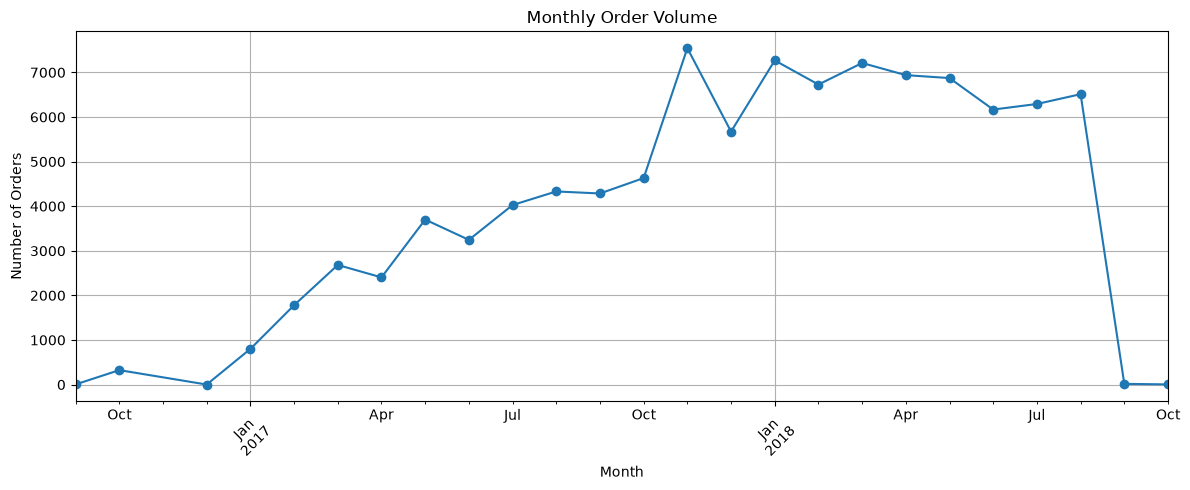

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("../visualizations/monthly_order_volume.png", dpi=300, bbox_inches="tight")
plt.show()

In [38]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [39]:
customers.shape

(99441, 5)

In [40]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [41]:
customers["customer_unique_id"].nunique()

96096

In [42]:
customers["customer_unique_id"].count() - customers["customer_unique_id"].nunique()

np.int64(3345)

In [43]:
customers["customer_unique_id"].value_counts().value_counts().sort_index()

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

### Finding: Customer Identifier Analysis

The customers dataset contains 99,441 records and 96,096 distinct `customer_unique_id` values. Every `customer_id` is unique, but 2,997 unique customers appear in multiple records.

Most customers (93,099) appear once, while one customer appears in 17 records. These repeated identifiers may be useful for investigating customer purchasing behavior, but actual repeat purchases should be confirmed by linking customer records to orders.

In [44]:
customers["customer_state"].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [ ]:
### Finding: Customer Distribution by State

Customer records are concentrated in southeastern Brazil, particularly São Paulo (SP), which has 41,746 records, approximately 42% of the dataset. Rio de Janeiro (RJ) follows with 12,852 records, and Minas Gerais (MG) has 11,635.

This geographic concentration may be relevant when analyzing regional sales and delivery performance. These counts represent customer records rather than distinct individuals.

In [45]:
customers["customer_city"].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

### Finding: Top Customer Cities

São Paulo is the most represented city, with 15,540 customer records, followed by Rio de Janeiro with 6,882. The top 10 cities account for approximately 35% of all customer records.

The results suggest that Olist's customer records are concentrated in major urban centers, especially in southeastern Brazil. These counts represent customer records, not necessarily distinct individuals.

In [46]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

### Finding: Missing Values in Customer Data

The customers dataset contains no missing values across its five columns: `customer_id`, `customer_unique_id`, `customer_zip_code_prefix`, `customer_city`, and `customer_state`.

All customer records have their identifiers and location fields populated. Further validation may still be needed to confirm that the recorded values are accurate and consistent.

In [47]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [48]:
order_items.shape

(112650, 7)

In [49]:
order_items["order_id"].nunique()

98666

In [50]:
order_items.duplicated().sum()

np.int64(0)

### Order Items Dataset — Initial Findings

- The dataset contains 112,650 rows and 7 columns.
- It represents 98,666 unique orders.
- The dataset contains no exact duplicate rows.
- The number of rows exceeds the number of unique orders because an order can contain multiple items.
- The orders dataset contains 99,441 unique orders, so some orders have no corresponding records in the order items dataset. This may affect later sales calculations and should be investigated before drawing conclusions.

In [51]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

### Order Items Dataset — Missing Values

- All seven columns contain zero missing values.
- The `price` and `freight_value` columns are available for all records, allowing us to proceed with initial sales and shipping cost analysis.
- Although no missing values were found, other data-quality checks are still needed before drawing business conclusions.

In [52]:
order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


### Order Items Dataset — Price and Freight Analysis

- The average item price is R$120.65, while the median is R$74.99.
- The middle 50% of item prices range from R$39.90 to R$134.90.
- The maximum item price is R$6,735.00, suggesting that high-priced items may influence the average.
- The average freight value is R$19.99, with a median of R$16.26.
- Freight values range from R$0.00 to R$409.68.
- Zero freight values and unusually high prices or shipping costs should be investigated before making further business conclusions.

In [53]:
(order_items["freight_value"] == 0).sum()

np.int64(383)

In [54]:
order_items[order_items["freight_value"] == 0].head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0


### Order Items Dataset — Zero Freight Values

- There are 383 item records with a freight value of R$0.00, representing approximately 0.34% of all item records.
- Sample records have valid-looking item prices despite having zero freight costs.
- Some orders contain multiple items with zero freight values.
- These records will be retained for now because zero freight does not necessarily indicate a data error. Their business meaning remains unconfirmed.

In [55]:
order_items.dtypes

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

In [56]:
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

In [57]:
order_items.dtypes

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

### Order Items Dataset — Data Types

- `order_id`, `product_id`, and `seller_id` are strings, which is appropriate for identifiers.
- `order_item_id` is an integer.
- `price` and `freight_value` are numeric columns suitable for calculations.
- `shipping_limit_date` was converted from a string to a datetime type for future date-based analysis.
- No missing values or exact duplicate rows were found in the initial checks.

In [58]:
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [59]:
payments.shape

(103886, 5)

In [60]:
payments["order_id"].nunique()

99440

In [61]:
payments.duplicated().sum()

np.int64(0)

In [62]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [63]:
payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

### Payments Dataset — Payment Methods

- The dataset contains 103,886 payment records representing 99,440 unique orders.
- Credit cards are the most common payment method, accounting for approximately 73.9% of payment records.
- Boleto accounts for approximately 19.0%, followed by vouchers at 5.6% and debit cards at 1.5%.
- Three records have a `not_defined` payment type.
- Payment method percentages are based on payment records, not unique orders or customers, because an order can have multiple payment records.

In [64]:
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

In [65]:
(payments["payment_value"] == 0).sum()

np.int64(9)

In [66]:
payments[payments["payment_value"] == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


### Payments Dataset — Payment Value Analysis

- The average payment value is R$154.10, while the median is R$100.00.
- The middle 50% of payment records range from R$56.79 to R$171.84.
- The maximum payment value is R$13,664.08, which may warrant further investigation.
- Nine payment records have a value of R$0.00, representing approximately 0.009% of all payment records.
- Of these, six use the voucher payment type and three use `not_defined`.
- The zero-value records will be retained for now because their cause has not yet been confirmed.

In [67]:
payments.dtypes

order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

### Payments Dataset — Data Types

- `order_id` and `payment_type` are stored as strings, which is appropriate.
- `payment_sequential` and `payment_installments` are integers.
- `payment_value` is numeric and suitable for calculations.
- All five columns have appropriate data types, so no conversions were necessary.
- Initial checks found no missing values or exact duplicate rows.

In [68]:
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [69]:
products.shape

(32951, 9)

In [70]:
products["product_id"].duplicated().sum()

np.int64(0)

In [71]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [72]:
products["product_category_name"].value_counts(dropna=False).head(10)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

In [73]:
products["product_category_name"].isnull().sum(), products["product_category_name"].notnull().sum()

(np.int64(610), np.int64(32341))

In [74]:
products[products["product_weight_g"].isnull()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
products.dtypes

product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

### Product Dataset — Initial Findings

- The dataset contains 32,951 product records and 9 columns.
- No duplicate product IDs were found.
- 610 products (approximately 1.85%) have missing category, name length, description length, and photo count values.
- Two products have missing weight and all three dimension measurements. One of these products also has all other attributes missing.
- The most common product category is `cama_mesa_banho`, with 3,029 products, followed by `esporte_lazer`, with 2,867.
- Numeric attributes are stored as `float64`, while product IDs and categories are stored as strings.
- Missing values will be retained for now and evaluated before analysis requiring those attributes.

In [76]:
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [77]:
reviews.shape

(99224, 7)

In [78]:
reviews["review_id"].duplicated().sum()

np.int64(814)

In [79]:
reviews[reviews["review_id"].duplicated(keep=False)].head(10)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
200,28642ce6250b94cc72bc85960aec6c62,e239d280236cdd3c40cb2c033f681d1c,5,NaN,NaN,2018-03-25 00:00:00,2018-03-25 21:03:02
344,a0a641414ff718ca079b3967ef5c2495,169d7e0fd71d624d306f132acd791cbe,5,NaN,NaN,2018-03-04 00:00:00,2018-03-06 20:12:53
346,f4d74b17cd63ee35efa82cd2567de911,f269e83a82f64baa3de97c2ebf3358f6,3,NaN,"A embalagem deixou a desejar, por pouco o prod...",2018-01-12 00:00:00,2018-01-13 18:46:10
360,ecbaf1fce7d2c09bfab46f89065afeaf,2451b9756f310d4cff5c7987b393870d,5,NaN,NaN,2017-07-27 00:00:00,2017-07-28 16:57:18
393,6b1de94de0f4bd84dfc4136818242faa,92acf87839903a94aeca0e5040d99acb,5,NaN,NaN,2018-02-16 00:00:00,2018-02-19 19:04:21
433,957011305e7a4b6c8a266eeeb8e0316d,54b4da510fed5dc3cf3e7a8e50a5f224,4,NaN,NaN,2018-03-10 00:00:00,2018-03-10 23:35:51
508,b34f4a786bf00b7c8486141ba482783b,b2501eb5c292d415f52576b3d4b5de74,3,NaN,NaN,2017-05-04 00:00:00,2017-05-22 12:02:34
661,d433c252647c51309432ca0b763f969b,448795135b904d057254f5fd0d5a6a4c,1,NaN,NaN,2017-09-03 00:00:00,2017-09-06 16:11:00
723,5f35bbde2b32b8617aab15b7a9a0ae24,ba568688e2f462d7c44a3fdc62e6456f,4,NaN,NaN,2017-11-26 00:00:00,2017-11-27 21:00:47
764,c5976a5a98e854fb23d7e03c6754ae60,2002ea16e75277eaa0b5d78632048540,5,NaN,NaN,2017-08-08 00:00:00,2017-08-10 11:11:29


In [80]:
duplicate_review_id = reviews.loc[
    reviews["review_id"].duplicated(),
    "review_id"
].iloc[0]

reviews[reviews["review_id"] == duplicate_review_id]

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
1009,3242cc306a9218d0377831e175d62fbf,711246846695fa895c1776f0ddc30b20,5,NaN,Ótimo,2017-07-21 00:00:00,2017-07-22 01:06:37
3317,3242cc306a9218d0377831e175d62fbf,9c5bfba7de6a4abbb6ba0baab78d1622,5,NaN,Ótimo,2017-07-21 00:00:00,2017-07-22 01:06:37


In [81]:
print("Total review records:", len(reviews))
print("Unique review IDs:", reviews["review_id"].nunique())
print("Unique order IDs:", reviews["order_id"].nunique())

Total review records: 99224
Unique review IDs: 98410
Unique order IDs: 98673


In [82]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [83]:
reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [84]:
reviews["review_score"].mean()

np.float64(4.08642062404257)

In [85]:
date_columns = [
    "review_creation_date",
    "review_answer_timestamp"
]

for column in date_columns:
    reviews[column] = pd.to_datetime(reviews[column], errors="coerce")

reviews.dtypes

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

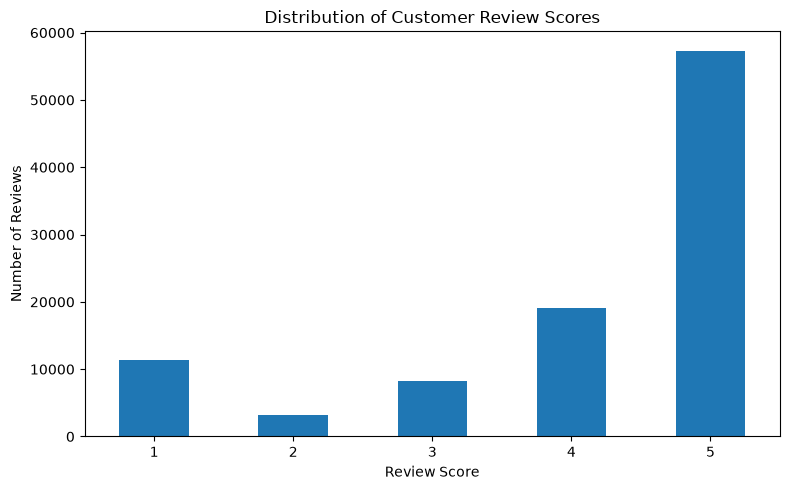

In [86]:
import matplotlib.pyplot as plt

review_counts = reviews["review_score"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
review_counts.plot(kind="bar")

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../visualizations/review_score_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Order Reviews Dataset — Initial Findings

- The dataset contains 99,224 review records and 7 columns.
- There are 98,410 unique review IDs and 98,673 unique order IDs. Some review IDs appear more than once, including cases where the same review details are associated with different orders. These records will be investigated further before any removal.
- The `review_score` column has no missing values.
- Review titles are missing in 87,656 records, and review messages are missing in 58,247 records. These may represent customers who submitted ratings without written feedback.
- The average review score is approximately 4.09 out of 5.
- Five-star reviews are the most common, with 57,328 records (approximately 57.8%). One-star reviews account for 11,424 records (approximately 11.5%).
- Both review date columns have been converted to datetime types.
- A bar chart of review scores was saved as `review_score_distribution.png`.
- Review ID duplication and missing written feedback will be considered during further analysis.

In [87]:
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [88]:
sellers.shape

(3095, 4)

In [89]:
sellers["seller_id"].duplicated().sum()

np.int64(0)

In [90]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [91]:
sellers["seller_state"].value_counts().head(10)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

In [92]:
sellers.dtypes

seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object

### Sellers Dataset — Initial Findings

- The dataset contains 3,095 seller records and 4 columns.
- No duplicate seller IDs were found.
- No missing values were found in any column.
- São Paulo (SP) has the most sellers, with 1,849 records (approximately 59.7% of all sellers).
- Paraná (PR) ranks second with 349 sellers, followed by Minas Gerais (MG) with 244.
- Seller IDs, cities, and states are stored as strings. Postal code prefixes are stored as integers and may be treated as strings if needed.
- Seller locations may be useful for analyzing geographic distribution and comparing seller locations with order activity.

In [93]:
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")

geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [94]:
geolocation.shape

(1000163, 5)

In [95]:
geolocation.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [96]:
geolocation.duplicated().sum()

np.int64(261831)

In [97]:
geolocation[geolocation.duplicated(keep=False)].head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [98]:
geolocation["geolocation_zip_code_prefix"].nunique()

19015

In [99]:
geolocation.dtypes

geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

### Geolocation Dataset — Initial Findings

- The dataset contains 1,000,163 rows and 5 columns.
- No missing values were found.
- There are 261,831 exact duplicate rows, approximately 26.2% of the dataset. These will be considered during data preparation.
- The dataset contains 19,015 unique postal code prefixes.
- A postal code prefix can appear with multiple geographic coordinates, so records should not be reduced to one row per prefix without a clear method.
- Latitude and longitude are stored as floating-point numbers, while city and state are stored as strings.
- Exact duplicate rows may need to be removed for analyses where repeated identical records could distort results. The original data will be preserved until cleaning decisions are made.

In [100]:
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [101]:
category_translation.shape

(71, 2)

In [102]:
category_translation.isnull().sum()

product_category_name            0
product_category_name_english    0
dtype: int64

In [103]:
category_translation["product_category_name"].duplicated().sum()

np.int64(0)

In [104]:
category_translation["product_category_name_english"].duplicated().sum()

np.int64(0)

### Product Category Translation Dataset — Initial Findings

- The dataset contains 71 rows and 2 columns.
- The columns are `product_category_name` and `product_category_name_english`.
- No missing values were found.
- No duplicate Portuguese category names were found.
- No duplicate English category names were found.
- This dataset maps Portuguese product categories to English, making category-based analysis and visualizations easier to understand.
- The translation table can later be merged with the products dataset using `product_category_name`.
- Product categories without a matching translation will need to be handled appropriately during data preparation.

In [105]:
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Order Items": order_items,
    "Payments": payments,
    "Products": products,
    "Reviews": reviews,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Orders: (99441, 10)
Customers: (99441, 5)
Order Items: (112650, 7)
Payments: (103886, 5)
Products: (32951, 9)
Reviews: (99224, 7)
Sellers: (3095, 4)
Geolocation: (1000163, 5)
Category Translation: (71, 2)


In [106]:
print("Orders:", orders["order_id"].nunique())
print("Order items:", len(order_items))
print("Unique orders in order items:", order_items["order_id"].nunique())

print(
    "Orders without matching order items:",
    len(set(orders["order_id"]) - set(order_items["order_id"]))
)

Orders: 99441
Order items: 112650
Unique orders in order items: 98666
Orders without matching order items: 775


In [107]:
orders_without_items = orders[
    ~orders["order_id"].isin(order_items["order_id"])
]

orders_without_items["order_status"].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [108]:
print(
    "Order items without a matching order:",
    len(set(order_items["order_id"]) - set(orders["order_id"]))
)

Order items without a matching order: 0


### Orders and Order Items — Relationship Findings

- The orders dataset contains 99,441 unique orders.
- The order items dataset contains 112,650 item records across 98,666 unique orders.
- There are 775 orders without matching item records.
- Of these 775 orders, 603 are unavailable and 164 are canceled. The remaining orders consist of 5 created, 2 invoiced, and 1 shipped.
- Every order ID in the order items dataset has a matching order ID in the orders dataset.
- This indicates that multiple item records can belong to one order, while some orders have no corresponding item records.
- Unmatched orders will be retained for now and handled carefully during later analysis.

In [109]:
print("Unique orders:", orders["order_id"].nunique())
print("Payment records:", len(payments))
print("Unique orders with payments:", payments["order_id"].nunique())

print(
    "Orders without matching payment records:",
    len(set(orders["order_id"]) - set(payments["order_id"]))
)

Unique orders: 99441
Payment records: 103886
Unique orders with payments: 99440
Orders without matching payment records: 1


In [110]:
orders_without_payments = orders[
    ~orders["order_id"].isin(payments["order_id"])
]

orders_without_payments[
    ["order_id", "order_status", "order_purchase_timestamp"]
]

,order_id,order_status,order_purchase_timestamp
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38


In [111]:
order_id_missing_payment = orders_without_payments["order_id"].iloc[0]

order_items[
    order_items["order_id"] == order_id_missing_payment
]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
84389,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84390,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84391,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83


In [112]:
payment_counts = payments["order_id"].value_counts()

print("Orders with multiple payment records:", (payment_counts > 1).sum())
print("Maximum payment records for one order:", payment_counts.max())

Orders with multiple payment records: 2961
Maximum payment records for one order: 29


### Orders and Payments — Relationship Findings

- The orders dataset contains 99,441 unique orders.
- The payments dataset contains 103,886 payment records across 99,440 unique orders.
- One order has no matching payment record. It is marked as delivered and has three item records in the order items dataset.
- A total of 2,961 orders have multiple payment records.
- The maximum number of payment records associated with a single order is 29.
- Multiple payment records per order mean that directly joining payments to other order-level tables can duplicate rows and inflate totals.
- Payment records should be aggregated by order when appropriate, and the order without a payment record should be flagged for further investigation.

In [113]:
print("Products in catalog:", products["product_id"].nunique())
print("Unique products in order items:", order_items["product_id"].nunique())

print(
    "Order item products missing from catalog:",
    len(set(order_items["product_id"]) - set(products["product_id"]))
)

Products in catalog: 32951
Unique products in order items: 32951
Order item products missing from catalog: 0


In [114]:
print("Sellers in catalog:", sellers["seller_id"].nunique())
print("Unique sellers in order items:", order_items["seller_id"].nunique())

print(
    "Order item sellers missing from catalog:",
    len(set(order_items["seller_id"]) - set(sellers["seller_id"]))
)

Sellers in catalog: 3095
Unique sellers in order items: 3095
Order item sellers missing from catalog: 0


### Order Items, Products, and Sellers — Relationship Findings

- The products catalog contains 32,951 unique products, all of which appear in the order items dataset.
- No product IDs referenced by order items are missing from the products catalog.
- The sellers catalog contains 3,095 unique sellers, all of whom appear in the order items dataset.
- No seller IDs referenced by order items are missing from the sellers catalog.
- These relationships allow order items to be enriched with product and seller information.
- When joining these tables, the order items table should remain at the item-record level unless the analysis requires aggregation.

In [115]:
print("Orders:", orders["order_id"].nunique())
print("Unique customers in orders:", orders["customer_id"].nunique())
print("Customer records:", customers["customer_id"].nunique())

print(
    "Orders with missing customer records:",
    len(set(orders["customer_id"]) - set(customers["customer_id"]))
)

Orders: 99441
Unique customers in orders: 99441
Customer records: 99441
Orders with missing customer records: 0


In [116]:
print("Review records:", len(reviews))
print("Unique orders with reviews:", reviews["order_id"].nunique())

print(
    "Reviews with missing order records:",
    len(set(reviews["order_id"]) - set(orders["order_id"]))
)

Review records: 99224
Unique orders with reviews: 98673
Reviews with missing order records: 0


In [117]:
review_counts = reviews["order_id"].value_counts()

print("Orders with multiple review records:", (review_counts > 1).sum())
print("Maximum review records for one order:", review_counts.max())

Orders with multiple review records: 547
Maximum review records for one order: 3


### Orders, Customers, and Reviews — Relationship Findings

- The orders dataset contains 99,441 unique orders, each with a distinct `customer_id`.
- Every order references a customer record in the customers dataset.
- The reviews dataset contains 99,224 review records across 98,673 unique orders.
- No review records reference an order missing from the orders dataset.
- A total of 547 orders have multiple review records, with a maximum of 3 records for one order.
- The reviews dataset also contains duplicate `review_id` values, so review records should be investigated before removing duplicates.
- When combining reviews with orders, multiple review records per order must be considered to avoid unintentionally duplicating order-level counts.



In [118]:
product_categories = set(
    products["product_category_name"].dropna()
)

translated_categories = set(
    category_translation["product_category_name"]
)

print("Unique product categories:", len(product_categories))
print("Available translations:", len(translated_categories))
print(
    "Categories without English translations:",
    len(product_categories - translated_categories)
)

Unique product categories: 73
Available translations: 71
Categories without English translations: 2


In [119]:
product_categories - translated_categories

{'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

### Product Categories — Translation Coverage Findings

- The products dataset contains 73 unique non-missing product categories.
- The translation dataset contains 71 category mappings.
- Two categories have no English translation: `pc_gamer` and `portateis_cozinha_e_preparadores_de_alimentos`.
- These categories will be preserved during data preparation. If needed, we can manually map them to readable English labels for visualizations.
- Missing category names in the products dataset are a separate issue and should be handled separately from categories that lack translations.

In [120]:
orders_clean = orders.copy()
customers_clean = customers.copy()
order_items_clean = order_items.copy()
payments_clean = payments.copy()
products_clean = products.copy()
reviews_clean = reviews.copy()
sellers_clean = sellers.copy()
geolocation_clean = geolocation.copy()
category_translation_clean = category_translation.copy()

print("Working copies created successfully.")

Working copies created successfully.


In [121]:
print(
    "Duplicate order IDs:",
    orders_clean["order_id"].duplicated().sum()
)

Duplicate order IDs: 0


In [122]:
orders_clean.isnull().sum()


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
purchase_year                       0
purchase_month                      0
dtype: int64

In [123]:
orders_clean.groupby("order_status")[
    "order_delivered_customer_date"
].apply(lambda column: column.isnull().sum()).sort_values(
    ascending=False
)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: order_delivered_customer_date, dtype: int64

In [124]:
orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].isnull())
][[
    "order_id",
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]]

,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-07-03 19:26:00,NaT,2018-07-19


### Orders Dataset — Cleaning Findings

- No duplicate `order_id` values were found.
- Missing values exist in three date columns: `order_approved_at` (160), `order_delivered_carrier_date` (1,783), and `order_delivered_customer_date` (2,965).
- Most missing customer delivery dates belong to orders that are not marked as delivered.
- Eight orders marked as delivered have missing customer delivery dates. Seven have a recorded carrier delivery date, while one has neither delivery date.
- These missing timestamps will be retained as missing values for now. They will not be filled with guessed dates or removed without a clear analytical reason.
- Missing delivery dates should be considered when calculating delivery times or evaluating delivery performance.

In [125]:
orders_clean["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [126]:
print(
    "Missing purchase timestamps:",
    orders_clean["order_purchase_timestamp"].isnull().sum()
)

print(
    "Year mismatches:",
    (
        orders_clean["purchase_year"] !=
        orders_clean["order_purchase_timestamp"].dt.year
    ).sum()
)

print(
    "Month mismatches:",
    (
        orders_clean["purchase_month"] !=
        orders_clean["order_purchase_timestamp"].dt.to_period("M")
    ).sum()
)

Missing purchase timestamps: 0
Year mismatches: 0
Month mismatches: 0


### Orders Dataset — Additional Cleaning Checks

- No duplicate order IDs were found.
- All eight order statuses match the expected values identified during exploration.
- No purchase timestamps are missing.
- The derived `purchase_year` and `purchase_month` columns match the original purchase timestamps for all records.
- No changes were required for order IDs, order statuses, or purchase timestamps.
- Missing approval and delivery timestamps remain unchanged pending further analysis.

In [127]:
print(
    "Duplicate customer IDs:",
    customers_clean["customer_id"].duplicated().sum()
)

Duplicate customer IDs: 0


In [128]:
customers_clean.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [129]:
customers_clean["customer_state"].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [130]:
customers_clean["customer_zip_code_prefix"].dtype

dtype('int64')

In [131]:
customers_clean["customer_zip_code_prefix"] = (
    customers_clean["customer_zip_code_prefix"].astype(str)
)

customers_clean["customer_zip_code_prefix"].dtype

<StringDtype(storage='python', na_value=nan)>

In [132]:
customers_clean["customer_zip_code_prefix"].str.len().value_counts()

customer_zip_code_prefix
5    75446
4    23995
Name: count, dtype: int64

In [133]:
customers_clean["customer_zip_code_prefix"] = (
    customers_clean["customer_zip_code_prefix"].str.zfill(5)
)

customers_clean["customer_zip_code_prefix"].str.len().value_counts()

customer_zip_code_prefix
5    99441
Name: count, dtype: int64

In [134]:
print("Customer records:", len(customers_clean))
print("Unique customer IDs:", customers_clean["customer_id"].nunique())
print("Unique underlying customers:", customers_clean["customer_unique_id"].nunique())

Customer records: 99441
Unique customer IDs: 99441
Unique underlying customers: 96096


### Customer Dataset Cleaning Findings

- No duplicate `customer_id` values were found.
- No missing values were found in the five customer columns.
- The dataset contains 27 distinct Brazilian state codes, with São Paulo (SP) having the most customer records.
- The ZIP code prefix column was converted from a numeric type to a string because it represents an identifier.
- ZIP code prefixes originally had either four or five characters. Leading zeros were restored using `str.zfill(5)`, resulting in five-character prefixes for all 99,441 records.
- The dataset contains 99,441 records and 96,096 unique underlying customers.
- The difference between customer records and unique underlying customers reflects customers who appear in multiple records, not necessarily duplicate data.

**Cleaning decision:** Keep all customer records. No rows need to be removed based on the checks performed.

In [135]:
print(
    "Exact duplicate order item rows:",
    order_items_clean.duplicated().sum()
)

Exact duplicate order item rows: 0


In [136]:
order_items_clean.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [137]:
order_items_clean.dtypes

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

In [138]:
order_items_clean[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [139]:
print("Zero prices:", (order_items_clean["price"] == 0).sum())
print("Negative prices:", (order_items_clean["price"] < 0).sum())

print("Zero freight values:", (order_items_clean["freight_value"] == 0).sum())
print("Negative freight values:", (order_items_clean["freight_value"] < 0).sum())

Zero prices: 0
Negative prices: 0
Zero freight values: 383
Negative freight values: 0


In [140]:
print(
    "Duplicate order-item combinations:",
    order_items_clean.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

Duplicate order-item combinations: 0


### Order Items Dataset Cleaning Findings

- No exact duplicate rows were found.
- No missing values were found in any of the seven columns.
- Data types were appropriate: identifiers are strings, `order_item_id` is an integer, `shipping_limit_date` is a datetime, and prices are numeric.
- All item prices are positive; no zero or negative prices were found.
- No negative freight values were found.
- There are 383 records with zero freight value, approximately 0.34% of all item rows. These were retained because they may represent valid free-shipping cases.
- No duplicate combinations of `order_id` and `order_item_id` were found.
- High prices and freight values were retained because unusual values are not necessarily errors.

**Cleaning decision:** No rows were removed. The dataset passed the checks performed, and zero-freight records were retained for further analysis.

In [141]:
print(
    "Exact duplicate payment rows:",
    payments_clean.duplicated().sum()
)

Exact duplicate payment rows: 0


In [142]:
payments_clean.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [143]:
payments_clean["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [144]:
payments_clean[["payment_value", "payment_installments"]].describe()

,payment_value,payment_installments
count,103886.000000,103886.000000
mean,154.100380,2.853349
std,217.494064,2.687051
min,0.000000,0.000000
25%,56.790000,1.000000
50%,100.000000,1.000000
75%,171.837500,4.000000
max,13664.080000,24.000000


In [145]:
print("Zero payment values:", (payments_clean["payment_value"] == 0).sum())
print("Negative payment values:", (payments_clean["payment_value"] < 0).sum())

print("Zero installments:", (payments_clean["payment_installments"] == 0).sum())
print("Negative installments:", (payments_clean["payment_installments"] < 0).sum())

Zero payment values: 9
Negative payment values: 0
Zero installments: 2
Negative installments: 0


In [146]:
payments_clean.loc[
    payments_clean["payment_installments"] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [147]:
payments_clean.loc[
    payments_clean["payment_value"] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


### Payments Dataset Cleaning Findings

- No exact duplicate payment rows were found.
- No missing values were found in the five columns.
- Five payment types were found: credit card, boleto, voucher, debit card, and `not_defined`.
- Three records use the `not_defined` payment type; these were retained rather than assigned an assumed payment method.
- Nine records have a payment value of zero: six vouchers and three `not_defined` records. These were retained for further investigation.
- No negative payment values were found.
- Two credit card records have zero installments despite having positive payment values. These were flagged as unusual and retained without correction.
- Payment values range from 0 to 13,664.08, and installment counts range from 0 to 24. Unusually high values were not automatically removed.
- Orders may have multiple payment records, so payment rows should be aggregated appropriately when calculating order-level totals to avoid double-counting.

**Cleaning decision:** No payment records were removed or modified. Unusual values and undefined payment types were retained and documented for further analysis.

In [148]:
print(
    "Exact duplicate product rows:",
    products_clean.duplicated().sum()
)

Exact duplicate product rows: 0


In [149]:
products_clean.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [150]:
products_clean.loc[
    products_clean["product_category_name"].isnull()
].head(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [151]:
missing_category = products_clean[
    products_clean["product_category_name"].isnull()
]

print("Products missing category:", len(missing_category))
print("Also missing name length:", missing_category["product_name_lenght"].isnull().sum())
print("Also missing description length:", missing_category["product_description_lenght"].isnull().sum())
print("Also missing photo count:", missing_category["product_photos_qty"].isnull().sum())

Products missing category: 610
Also missing name length: 610
Also missing description length: 610
Also missing photo count: 610


In [152]:
products_clean.loc[
    products_clean["product_weight_g"].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [153]:
products_clean["product_category_name"].value_counts().head(15)

product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
papelaria                       849
fashion_bolsas_e_acessorios     849
cool_stuff                      789
Name: count, dtype: int64

### Products Dataset Cleaning Findings

- No exact duplicate product rows were found.
- There are 610 products missing their category, name length, description length, and photo count. These missing values occur together.
- The 610 incomplete products were retained because their product IDs remain available and some still have physical measurements.
- Two products have missing weight and dimensions. One has other attributes available, while the other has only its product ID populated.
- Missing measurements and product attributes were left unchanged rather than replaced with guessed values.
- The most common category labels appear consistent and use Portuguese names. Category translations can be applied later for reporting.
- The original column names `product_name_lenght` and `product_description_lenght` contain spelling mistakes. They were retained for now to avoid breaking references in the notebook; they can be renamed later if needed.

**Cleaning decision:** No product rows were removed, and no missing attributes were imputed. Incomplete records were retained for further analysis.

In [154]:
print(
    "Exact duplicate seller rows:",
    sellers_clean.duplicated().sum()
)

Exact duplicate seller rows: 0


In [155]:
sellers_clean.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [156]:
sellers_clean["seller_zip_code_prefix"].dtype

dtype('int64')

In [157]:
sellers_clean["seller_zip_code_prefix"] = (
    sellers_clean["seller_zip_code_prefix"].astype("string")
)

sellers_clean["seller_zip_code_prefix"].dtype

<StringDtype(storage='python', na_value=<NA>)>

In [158]:
sellers_clean["seller_zip_code_prefix"].str.len().value_counts()

seller_zip_code_prefix
5    2068
4    1027
Name: count, dtype: Int64

In [159]:
sellers_clean["seller_zip_code_prefix"] = (
    sellers_clean["seller_zip_code_prefix"].str.zfill(5)
)

sellers_clean["seller_zip_code_prefix"].str.len().value_counts()

seller_zip_code_prefix
5    3095
Name: count, dtype: Int64

In [160]:
sellers_clean["seller_state"].value_counts()

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

### Sellers Dataset Cleaning Findings

- No exact duplicate seller rows were found.
- No missing values were found in the four seller columns.
- The seller ZIP code prefix column was converted from a numeric type to a string because it represents an identifier.
- ZIP code prefixes originally had either four or five characters. Leading zeros were restored using `str.zfill(5)`, resulting in five-character prefixes for all 3,095 sellers.
- The dataset contains 23 distinct state codes. São Paulo (SP) has the largest number of sellers.
- Seller state values appear consistent, and no obvious invalid codes were identified.

**Cleaning decision:** No seller rows were removed. ZIP code prefixes were standardized, and the remaining columns were retained unchanged.

In [162]:
print(
    "Exact duplicate review rows:",
    reviews_clean.duplicated().sum()
)

Exact duplicate review rows: 0


In [163]:
reviews_clean.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [164]:
reviews_clean["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [165]:
print(
    "Duplicate review IDs:",
    reviews_clean["review_id"].duplicated().sum()
)

Duplicate review IDs: 814


In [166]:
duplicate_reviews = reviews_clean[
    reviews_clean["review_id"].duplicated(keep=False)
].sort_values("review_id")

duplicate_reviews.head(10)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


In [167]:
duplicate_review_summary = (
    duplicate_reviews
    .groupby("review_id")
    .agg(
        row_count=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
        unique_creation_dates=("review_creation_date", "nunique"),
        unique_answer_timestamps=("review_answer_timestamp", "nunique")
    )
)

duplicate_review_summary.head(10)

,row_count,unique_orders,unique_scores,unique_creation_dates,unique_answer_timestamps
review_id,,,,,
00130cbe1f9d422698c812ed8ded1919,2,2,1,1,1
0115633a9c298b6a98bcbe4eee75345f,2,2,1,1,1
0174caf0ee5964646040cd94e15ac95e,2,2,1,1,1
017808d29fd1f942d97e50184dfb4c13,2,2,1,1,1
0254bd905dc677a6078990aad3331a36,2,2,1,1,1
0288d42bef3dfe36930740c9588a570f,2,2,1,1,1
02aa7f5f75e964e3c7efa59a1f515281,2,2,1,1,1
034528cb00b6bc981847acafbdf2ae0b,2,2,1,1,1
03a6a25db577d0689440933055111897,2,2,1,1,1


In [168]:
print(
    "Duplicated review IDs with different scores:",
    (duplicate_review_summary["unique_scores"] > 1).sum()
)

print(
    "Duplicated review IDs with different creation dates:",
    (duplicate_review_summary["unique_creation_dates"] > 1).sum()
)

print(
    "Duplicated review IDs with different answer timestamps:",
    (duplicate_review_summary["unique_answer_timestamps"] > 1).sum()
)

Duplicated review IDs with different scores: 0
Duplicated review IDs with different creation dates: 0
Duplicated review IDs with different answer timestamps: 0


### Reviews Dataset Cleaning Findings

- No exact duplicate review rows were found.
- Missing values were found in `review_comment_title` (87,656) and `review_comment_message` (58,247). These were retained because customers may submit ratings without written comments.
- All review scores are within the expected range of 1 to 5.
- There are 814 rows with duplicated `review_id` values.
- The duplicated review IDs examined have consistent scores, creation dates, and answer timestamps, but reference different orders.
- No duplicated review IDs have conflicting scores, creation dates, or answer timestamps.
- Duplicate review IDs were retained because their cause has not been established.
- Review creation dates and answer timestamps were retained for future analysis.

**Cleaning decision:** No review rows were removed. Missing comments were retained, scores were verified, and duplicated review IDs were flagged for further investigation. When analyzing reviews, account for the possibility that repeated review IDs may affect counts.

In [169]:
print(
    "Exact duplicate geolocation rows:",
    geolocation_clean.duplicated().sum()
)

Exact duplicate geolocation rows: 261831


In [170]:
print("Original rows and columns:", geolocation.shape)
print("Rows after exact duplicates are removed:", len(geolocation.drop_duplicates()))

Original rows and columns: (1000163, 5)
Rows after exact duplicates are removed: 738332


In [171]:
geolocation_clean.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [172]:
geolocation_clean.dtypes

geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

In [173]:
geolocation_clean["geolocation_zip_code_prefix"] = (
    geolocation_clean["geolocation_zip_code_prefix"]
    .astype("string")
    .str.zfill(5)
)

geolocation_clean["geolocation_zip_code_prefix"].str.len().value_counts()

geolocation_zip_code_prefix
5    1000163
Name: count, dtype: Int64

In [174]:
geolocation_clean = geolocation_clean.drop_duplicates().copy()

print("Shape after removing duplicates:", geolocation_clean.shape)
print("Remaining exact duplicate rows:", geolocation_clean.duplicated().sum())

Shape after removing duplicates: (738332, 5)
Remaining exact duplicate rows: 0


### Geolocation Dataset Cleaning Findings

- The original dataset contained 1,000,163 rows and five columns.
- No missing values were found.
- The ZIP code prefix column was converted from an integer to a string because it represents an identifier.
- All ZIP code prefixes were standardized to five characters using `str.zfill(5)`.
- There were 261,831 exact duplicate rows, which were removed.
- The cleaned dataset contains 738,332 rows and no remaining exact duplicates.
- Latitude and longitude were retained as numeric values for geographic analysis.
- Multiple records with the same ZIP code prefix were retained when their other values differed.

**Cleaning decision:** Exact duplicate rows were removed, ZIP code prefixes were standardized, and all remaining records were preserved for potential geographic analysis.

In [175]:
print("Dataset shape:", category_translation_clean.shape)
print("\nMissing values:")
print(category_translation_clean.isnull().sum())

Dataset shape: (71, 2)

Missing values:
product_category_name            0
product_category_name_english    0
dtype: int64


In [176]:
print(
    "Exact duplicate rows:",
    category_translation_clean.duplicated().sum()
)

print(
    "Duplicate Portuguese category names:",
    category_translation_clean["product_category_name"].duplicated().sum()
)

Exact duplicate rows: 0
Duplicate Portuguese category names: 0


In [177]:
category_translation_clean.head(10)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
5,esporte_lazer,sports_leisure
6,perfumaria,perfumery
7,utilidades_domesticas,housewares
8,telefonia,telephony
9,relogios_presentes,watches_gifts


### Product Category Translation Cleaning Findings

- The dataset contains 71 product category mappings across two columns.
- No missing values were found.
- No exact duplicate rows were found.
- No duplicate Portuguese category names were found.
- The inspected mappings appear consistent, with Portuguese category names matched to English translations.
- The English translations use underscores, which can be retained for data processing and formatted later for visualization.

**Cleaning decision:** No rows were removed or modified. The dataset is ready to be used for translating product categories during analysis.

In [178]:
cleaned_datasets = {
    "Orders": orders_clean,
    "Customers": customers_clean,
    "Order Items": order_items_clean,
    "Payments": payments_clean,
    "Products": products_clean,
    "Reviews": reviews_clean,
    "Sellers": sellers_clean,
    "Geolocation": geolocation_clean,
    "Category Translation": category_translation_clean
}

for name, df in cleaned_datasets.items():
    print(f"{name}: {df.shape}")

Orders: (99441, 10)
Customers: (99441, 5)
Order Items: (112650, 7)
Payments: (103886, 5)
Products: (32951, 9)
Reviews: (99224, 7)
Sellers: (3095, 4)
Geolocation: (738332, 5)
Category Translation: (71, 2)


In [179]:
for name, df in cleaned_datasets.items():
    print(f"\n{name}")
    print("  Missing values:", df.isnull().sum().sum())
    print("  Exact duplicate rows:", df.duplicated().sum())


Orders
  Missing values: 4908
  Exact duplicate rows: 0

Customers
  Missing values: 0
  Exact duplicate rows: 0

Order Items
  Missing values: 0
  Exact duplicate rows: 0

Payments
  Missing values: 0
  Exact duplicate rows: 0

Products
  Missing values: 2448
  Exact duplicate rows: 0

Reviews
  Missing values: 145903
  Exact duplicate rows: 0

Sellers
  Missing values: 0
  Exact duplicate rows: 0

Geolocation
  Missing values: 0
  Exact duplicate rows: 0

Category Translation
  Missing values: 0
  Exact duplicate rows: 0


### Overall Data Cleaning Summary

- All nine datasets were inspected for missing values, exact duplicate rows, and relevant data-quality issues.
- Exact duplicate rows were removed from the geolocation dataset, reducing it from 1,000,163 to 738,332 rows.
- ZIP code prefixes in the customers, sellers, and geolocation datasets were converted to strings and standardized to five characters.
- Date columns were converted to datetime types where needed.
- Missing timestamps in orders, optional review comments, and incomplete product attributes were retained because they may represent legitimate missing information.
- Duplicate review IDs were investigated and retained because their cause has not been established.
- Unusual payment values, zero freight charges, and other potentially meaningful records were retained for further analysis rather than removed without evidence.
- Relationship checks were performed across orders, customers, order items, payments, products, sellers, and reviews.

**Overall decision:** The datasets are prepared for the next stage of the project. Remaining missing values and unusual records will be handled according to the requirements of each analysis rather than removed indiscriminately.

In [180]:
from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

for name, df in cleaned_datasets.items():
    filename = name.lower().replace(" ", "_") + ".csv"
    df.to_csv(output_folder / filename, index=False)
    print(f"Saved: {filename} — {df.shape[0]:,} rows")

Saved: orders.csv — 99,441 rows
Saved: customers.csv — 99,441 rows
Saved: order_items.csv — 112,650 rows
Saved: payments.csv — 103,886 rows
Saved: products.csv — 32,951 rows
Saved: reviews.csv — 99,224 rows
Saved: sellers.csv — 3,095 rows
Saved: geolocation.csv — 738,332 rows
Saved: category_translation.csv — 71 rows


In [181]:
for name in cleaned_datasets:
    filename = name.lower().replace(" ", "_") + ".csv"
    file_path = output_folder / filename

    print(
        f"{filename}:",
        "Exists" if file_path.exists() else "Missing"
    )

orders.csv: Exists
customers.csv: Exists
order_items.csv: Exists
payments.csv: Exists
products.csv: Exists
reviews.csv: Exists
sellers.csv: Exists
geolocation.csv: Exists
category_translation.csv: Exists


In [1]:
import pandas as pd

review_comments = pd.read_csv(
    "../data/processed/review_comments_for_analysis.csv"
)

print("Dataset shape:", review_comments.shape)
review_comments.head()

Dataset shape: (40949, 4)


,358f8960d56c93578361c94ad748da07,1e96a45243abd1f2da33000b50e61c50,1,Péssima entrega
0,314a06cfaa224a122552d2c76a754618,5fbaa35725c08e8527b1bcae123d2490,1,Comprei uma elevação de acento com forro no as...
1,0bb0275b3ba4ff9c8d8937908029c5d1,9b2504f4428a8a4d047d22a966df321d,1,"no anuncio um aparelho original TCL, o que eu..."
2,3498dac22d14abc04a51f99e321409a4,4f7dbee2068ee41007872df9d2532dfa,1,Empresa não é pontual na entrega.
3,1e521b900babad98764b25b81781ee7d,f65abc0b3f3401b14505a57fb6113cf1,1,Cor divergente: pedi azul turquesa e veio verd...
4,6c13a8aa5925745be1de7afc96648c14,464903700caac1e06ce732afb660cfe2,1,Só recebi a cortina.. o rolo nao recebi.. e co...


In [2]:
review_comments = pd.read_csv(
    "../data/processed/review_comments_for_analysis.csv",
    header=None,
    names=[
        "review_id",
        "order_id",
        "review_score",
        "review_comment_message"
    ]
)

print("Dataset shape:", review_comments.shape)
display(review_comments.head())

Dataset shape: (40950, 4)


,review_id,order_id,review_score,review_comment_message
0,358f8960d56c93578361c94ad748da07,1e96a45243abd1f2da33000b50e61c50,1,Péssima entrega
1,314a06cfaa224a122552d2c76a754618,5fbaa35725c08e8527b1bcae123d2490,1,Comprei uma elevação de acento com forro no as...
2,0bb0275b3ba4ff9c8d8937908029c5d1,9b2504f4428a8a4d047d22a966df321d,1,"no anuncio um aparelho original TCL, o que eu..."
3,3498dac22d14abc04a51f99e321409a4,4f7dbee2068ee41007872df9d2532dfa,1,Empresa não é pontual na entrega.
4,1e521b900babad98764b25b81781ee7d,f65abc0b3f3401b14505a57fb6113cf1,1,Cor divergente: pedi azul turquesa e veio verd...


In [3]:
import re

review_comments["comment_clean"] = (
    review_comments["review_comment_message"]
    .astype(str)
    .str.lower()
    .apply(lambda text: re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE))
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

review_comments[
    ["review_comment_message", "comment_clean"]
].head(10)

,review_comment_message,comment_clean
0,Péssima entrega,péssima entrega
1,Comprei uma elevação de acento com forro no as...,comprei uma elevação de acento com forro no as...
2,"no anuncio um aparelho original TCL, o que eu...",no anuncio um aparelho original tcl o que eu r...
3,Empresa não é pontual na entrega.,empresa não é pontual na entrega
4,Cor divergente: pedi azul turquesa e veio verd...,cor divergente pedi azul turquesa e veio verde...
5,Só recebi a cortina.. o rolo nao recebi.. e co...,só recebi a cortina o rolo nao recebi e consta...
6,"Escolhi as taças com caveira mexicana, foram e...",escolhi as taças com caveira mexicana foram en...
7,"No anuncio diz ser 3 cores, mas veio com varia...",no anuncio diz ser 3 cores mas veio com varias...
8,O produto veio com defeito enviei email e nao ...,o produto veio com defeito enviei email e nao ...
9,nao posso avaliar pois ainda nao recebi.26/12/...,nao posso avaliar pois ainda nao recebi 26 12 ...


In [4]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

portuguese_stopwords = set(stopwords.words("portuguese"))

review_comments["comment_no_stopwords"] = (
    review_comments["comment_clean"]
    .apply(
        lambda text: " ".join(
            word for word in text.split()
            if word not in portuguese_stopwords
        )
    )
)

review_comments[
    ["comment_clean", "comment_no_stopwords"]
].head(10)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\cblil\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


,comment_clean,comment_no_stopwords
0,péssima entrega,péssima entrega
1,comprei uma elevação de acento com forro no as...,comprei elevação acento forro assento braços e...
2,no anuncio um aparelho original tcl o que eu r...,anuncio aparelho original tcl recebi sky funci...
3,empresa não é pontual na entrega,empresa pontual entrega
4,cor divergente pedi azul turquesa e veio verde...,cor divergente pedi azul turquesa veio verde p...
5,só recebi a cortina o rolo nao recebi e consta...,recebi cortina rolo nao recebi consta entregado 2
6,escolhi as taças com caveira mexicana foram en...,escolhi taças caveira mexicana entregues pôquer
7,no anuncio diz ser 3 cores mas veio com varias...,anuncio diz 3 cores veio varias cores
8,o produto veio com defeito enviei email e nao ...,produto veio defeito enviei email nao obtive r...
9,nao posso avaliar pois ainda nao recebi 26 12 ...,nao posso avaliar pois ainda nao recebi 26 12 ...


In [5]:
# Keep negation words so complaint meanings are not lost
negation_words = {"não", "nao", "nunca", "jamais"}

portuguese_stopwords = (
    set(stopwords.words("portuguese")) - negation_words
)

review_comments["comment_no_stopwords"] = (
    review_comments["comment_clean"]
    .apply(
        lambda text: " ".join(
            word for word in text.split()
            if word not in portuguese_stopwords
        )
    )
)

review_comments[
    ["comment_clean", "comment_no_stopwords"]
].head(10)

,comment_clean,comment_no_stopwords
0,péssima entrega,péssima entrega
1,comprei uma elevação de acento com forro no as...,comprei elevação acento forro assento braços e...
2,no anuncio um aparelho original tcl o que eu r...,anuncio aparelho original tcl recebi sky funci...
3,empresa não é pontual na entrega,empresa não pontual entrega
4,cor divergente pedi azul turquesa e veio verde...,cor divergente pedi azul turquesa veio verde p...
5,só recebi a cortina o rolo nao recebi e consta...,recebi cortina rolo nao recebi consta entregado 2
6,escolhi as taças com caveira mexicana foram en...,escolhi taças caveira mexicana entregues pôquer
7,no anuncio diz ser 3 cores mas veio com varias...,anuncio diz 3 cores veio varias cores
8,o produto veio com defeito enviei email e nao ...,produto veio defeito enviei email nao obtive r...
9,nao posso avaliar pois ainda nao recebi 26 12 ...,nao posso avaliar pois ainda nao recebi 26 12 ...


In [6]:
from collections import Counter

all_words = " ".join(
    review_comments["comment_no_stopwords"]
).split()

word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "frequency"]
)

top_words

,word,frequency
0,produto,18428
1,não,10787
2,prazo,8475
3,entrega,6528
4,antes,5626
5,chegou,5555
6,recebi,5274
7,bom,4607
8,recomendo,4337
9,entregue,3779


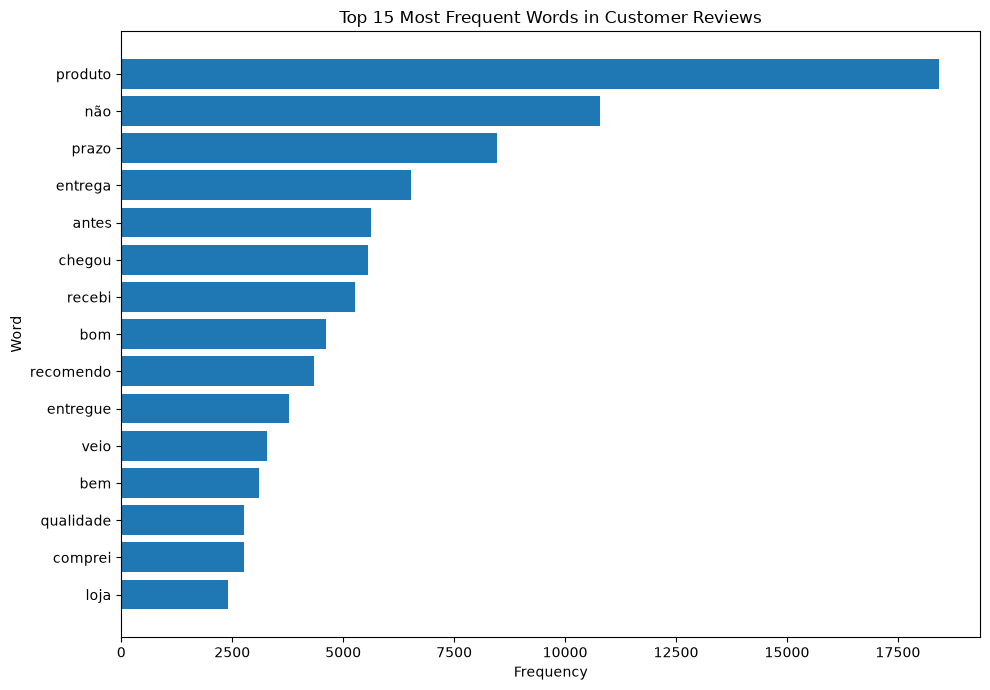

In [7]:
import matplotlib.pyplot as plt

top_15_words = top_words.head(15).sort_values("frequency")

plt.figure(figsize=(10, 7))
plt.barh(top_15_words["word"], top_15_words["frequency"])
plt.title("Top 15 Most Frequent Words in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    "../visualizations/top_review_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
from collections import Counter

low_rated_text = " ".join(
    review_comments.loc[
        review_comments["review_score"].isin([1, 2]),
        "comment_no_stopwords"
    ]
)

high_rated_text = " ".join(
    review_comments.loc[
        review_comments["review_score"].isin([4, 5]),
        "comment_no_stopwords"
    ]
)

low_rated_words = Counter(low_rated_text.split())
high_rated_words = Counter(high_rated_text.split())

low_rated_top20 = pd.DataFrame(
    low_rated_words.most_common(20),
    columns=["word", "frequency"]
)

high_rated_top20 = pd.DataFrame(
    high_rated_words.most_common(20),
    columns=["word", "frequency"]
)

print("Top words in 1–2 star reviews")
display(low_rated_top20)

print("Top words in 4–5 star reviews")
display(high_rated_top20)

Top words in 1–2 star reviews


,word,frequency
0,não,7483
1,produto,6189
2,recebi,3272
3,comprei,1882
4,veio,1552
5,entrega,1412
6,ainda,1401
7,entregue,1329
8,chegou,1180
9,nao,949


Top words in 4–5 star reviews


,word,frequency
0,produto,10645
1,prazo,7077
2,antes,5281
3,entrega,4633
4,chegou,4016
5,bom,4008
6,recomendo,3873
7,bem,2697
8,entregue,2165
9,qualidade,2162


In [9]:
low_rated_top20.to_csv(
    "../data/processed/top_words_low_rated_reviews.csv",
    index=False
)

high_rated_top20.to_csv(
    "../data/processed/top_words_high_rated_reviews.csv",
    index=False
)

print("Keyword comparison files saved.")

Keyword comparison files saved.


In [10]:
delivery_keywords = [
    "entrega",       # delivery
    "entregue",      # delivered
    "atraso",        # delay
    "atrasado",      # delayed
    "prazo",         # deadline / delivery time
    "chegou",        # arrived
    "recebi",        # received
    "receber",       # to receive
    "frete"          # shipping / freight
]

review_comments["mentions_delivery"] = (
    review_comments["comment_clean"]
    .apply(
        lambda text: any(
            keyword in text.split()
            for keyword in delivery_keywords
        )
    )
)

delivery_summary = (
    review_comments
    .groupby("review_score")["mentions_delivery"]
    .agg(total_reviews="count", reviews_mentioning_delivery="sum")
    .reset_index()
)

delivery_summary["percentage_mentioning_delivery"] = (
    delivery_summary["reviews_mentioning_delivery"]
    / delivery_summary["total_reviews"] * 100
).round(2)

delivery_summary

,review_score,total_reviews,reviews_mentioning_delivery,percentage_mentioning_delivery
0,1,8744,5182,59.26
1,2,2145,1111,51.79
2,3,3557,1587,44.62
3,4,5969,2651,44.41
4,5,20535,9939,48.40


In [11]:
delivery_summary.to_csv(
    "../data/processed/delivery_keyword_analysis.csv",
    index=False
)

print("Delivery keyword analysis saved.")

Delivery keyword analysis saved.


In [12]:
theme_keywords = {
    "product_quality": [
        "defeito", "quebrado", "quebrada",
        "danificado", "danificada", "qualidade",
        "funciona", "funcionando", "estragado",
        "estragada"
    ],
    "missing_or_wrong_item": [
        "faltou", "falta", "errado", "errada",
        "diferente", "incompleto", "incompleta",
        "faltando", "trocar", "troca"
    ]
}

for theme, keywords in theme_keywords.items():
    review_comments[f"mentions_{theme}"] = (
        review_comments["comment_clean"]
        .apply(
            lambda text: any(
                keyword in text.split()
                for keyword in keywords
            )
        )
    )

theme_summary = (
    review_comments
    .groupby("review_score")[
        ["mentions_product_quality", "mentions_missing_or_wrong_item"]
    ]
    .agg(["count", "sum"])
)

theme_summary

mentions_product_quality       mentions_missing_or_wrong_item  \
                                count   sum                          count   
review_score                                                                 
1                                8744   745                           8744   
2                                2145   240                           2145   
3                                3557   317                           3557   
4                                5969   515                           5969   
5                               20535  1923                          20535   

                    
               sum  
review_score        
1             1204  
2              310  
3              344  
4              225  
5              157

In [13]:
theme_summary_clean = (
    review_comments
    .groupby("review_score")
    .agg(
        total_reviews=("review_id", "count"),
        product_quality_mentions=("mentions_product_quality", "sum"),
        missing_or_wrong_item_mentions=("mentions_missing_or_wrong_item", "sum")
    )
    .reset_index()
)

theme_summary_clean["product_quality_mention_pct"] = (
    theme_summary_clean["product_quality_mentions"]
    / theme_summary_clean["total_reviews"] * 100
).round(2)

theme_summary_clean["missing_or_wrong_item_pct"] = (
    theme_summary_clean["missing_or_wrong_item_mentions"]
    / theme_summary_clean["total_reviews"] * 100
).round(2)

theme_summary_clean

,review_score,total_reviews,product_quality_mentions,missing_or_wrong_item_mentions,product_quality_mention_pct,missing_or_wrong_item_pct
0,1,8744,745,1204,8.52,13.77
1,2,2145,240,310,11.19,14.45
2,3,3557,317,344,8.91,9.67
3,4,5969,515,225,8.63,3.77
4,5,20535,1923,157,9.36,0.76


In [14]:
theme_summary_clean.to_csv(
    "../data/processed/review_theme_analysis.csv",
    index=False
)

print("Review theme analysis saved.")

Review theme analysis saved.


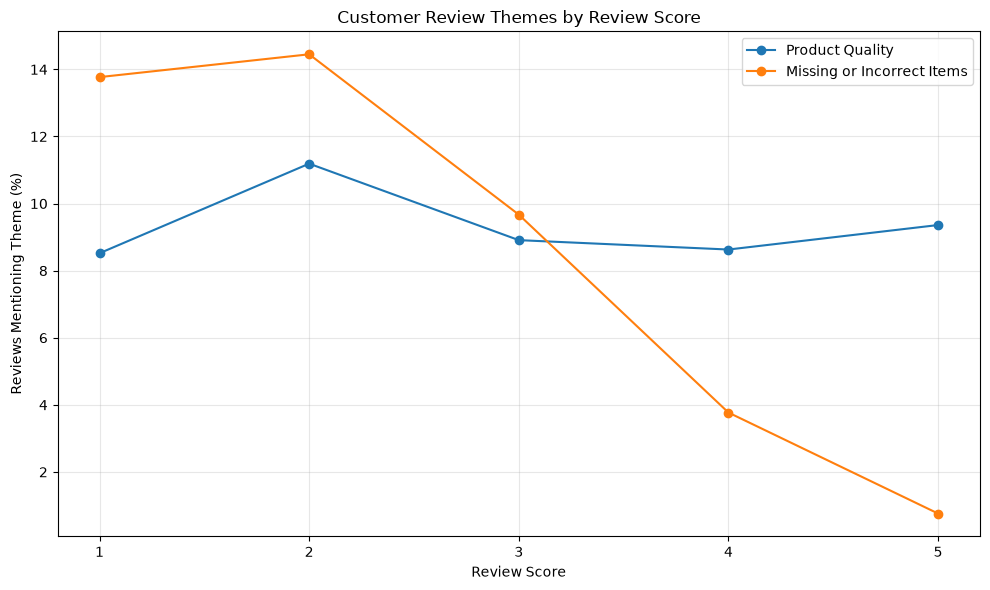

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    theme_summary_clean["review_score"],
    theme_summary_clean["product_quality_mention_pct"],
    marker="o",
    label="Product Quality"
)

plt.plot(
    theme_summary_clean["review_score"],
    theme_summary_clean["missing_or_wrong_item_pct"],
    marker="o",
    label="Missing or Incorrect Items"
)

plt.title("Customer Review Themes by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Reviews Mentioning Theme (%)")
plt.xticks([1, 2, 3, 4, 5])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/review_themes_by_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
import os

print("Visualization files:")
print(os.listdir("../visualizations"))

print("\nProcessed data files:")
print(os.listdir("../data/processed"))

Visualization files:
['monthly_order_volume.png', 'review_score_distribution.png', 'review_themes_by_score.png', 'top_review_words.png']

Processed data files:
['average_order_value.csv', 'average_price_by_category.csv', 'category_translation.csv', 'customers.csv', 'delivery_estimate_analysis.csv', 'delivery_keyword_analysis.csv', 'delivery_performance.csv', 'freight_by_category.csv', 'geolocation.csv', 'monthly_order_volume.csv', 'monthly_sales_revenue.csv', 'orders.csv', 'orders_by_customer_state.csv', 'order_items.csv', 'order_status_analysis.csv', 'order_value_by_payment_method.csv', 'payments.csv', 'payment_method_analysis.csv', 'products.csv', 'repeat_customer_analysis.csv', 'reviews.csv', 'reviews_by_delivery_performance.csv', 'review_comments_by_score.csv', 'review_comments_for_analysis.csv', 'review_comment_availability.csv', 'review_scores_by_category.csv', 'review_score_analysis.csv', 'review_theme_analysis.csv', 'sales_by_category.csv', 'sales_by_customer_state.csv', 'sales

## Key Findings: Olist E-Commerce Analysis

### Sales and Orders
- November 2017 had the highest monthly item sales revenue in the analyzed results, at approximately R$1.01 million.
- Health and beauty generated the highest category sales, at approximately R$1.26 million.
- São Paulo was the largest customer market, generating approximately R$5.20 million in item sales.

### Customer Experience
- Approximately 77.07% of reviews received a score of 4 or 5.
- Orders delivered late had an average review score of 2.57, compared with 4.29 for orders delivered on time or early.
- Missing or incorrect-item keywords appeared in 13.77% of 1-star reviews, compared with 0.76% of 5-star reviews.

### Business Opportunities
- Investigate delivery delays and order fulfillment issues to improve customer satisfaction.
- Review category-level performance to identify products that generate high sales but weaker customer ratings.
- Explore repeat-purchase opportunities, since approximately 3.12% of unique customers placed more than one order in the analyzed dataset.

### Limitations
- Revenue figures based on order items exclude freight and do not represent profit.
- The dataset covers a limited historical period, and the final months may be incomplete.
- Review keyword analysis identifies possible themes, not definitive causes of customer satisfaction or dissatisfaction.
